# Supplementary Figure S8 — SiO₂ versus K₂O

Standalone notebook for the anhydrous-normalized SiO₂–K₂O figure, previously numbered S1. It uses the publication settings from `Nov6_AllFigures/00_Setup`, contains no custom functions, and does not modify the source workbooks.

## Shared setup for Figure S8

This cell contains the environment, paths, Science Advances dimensions and typography, project colors, and approved marker geometry. Public users only need to change `DATA_DIRECTORY`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.lines import Line2D
from matplotlib.markers import MarkerStyle
from matplotlib.patches import Patch
from matplotlib.path import Path as MarkerPath
from IPython.display import display

DECHERT_DATA_DIRECTORY = Path('/Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/DataSheets/Updated_Oct20')
USER_DATA_DIRECTORY = Path('/replace/with/your/folder/containing/the/three/supplemental/files')
DATA_DIRECTORY = DECHERT_DATA_DIRECTORY
# DATA_DIRECTORY = USER_DATA_DIRECTORY

PROJECT_ROOT = None
for candidate in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    if candidate.name == 'Nov6_AllFigures':
        PROJECT_ROOT = candidate
        break
if PROJECT_ROOT is None:
    raise FileNotFoundError('Start in Nov6_AllFigures or one of its figure folders.')

FIGURE_DIRECTORY = PROJECT_ROOT / 'Figure_S08_SiO2_K2O'
OUTPUT_DIRECTORY = FIGURE_DIRECTORY / 'Figure_S08_SiO2_K2O_Final'
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
WORKBOOK_PATHS = {
    'S1': DATA_DIRECTORY / 'Dechert_S1_AllData.xlsx',
    'S2': DATA_DIRECTORY / 'Dechert_S2_Standards.xlsx',
    'S3': DATA_DIRECTORY / 'Dechert_S3_Compilations.xlsx',
}
for supplement, path in WORKBOOK_PATHS.items():
    if not path.is_file():
        raise FileNotFoundError(f'{supplement}: required supplemental file not found: {path}')

SINGLE_COLUMN_WIDTH_IN = 3.55
DOUBLE_COLUMN_WIDTH_IN = 7.25
MAXIMUM_INTERMEDIATE_WIDTH_IN = 5.67
MAXIMUM_RECOMMENDED_HEIGHT_IN = 7.8
BASE_TEXT_SIZE_PT = 8.0
AXIS_LABEL_SIZE_PT = 8.0
TICK_LABEL_SIZE_PT = 8.0
LEGEND_SIZE_PT = 8.0
LEGEND_TITLE_SIZE_PT = 8.0
ANNOTATION_SIZE_PT = 8.0
PANEL_LABEL_SIZE_PT = 9.0
MINIMUM_LINE_WIDTH_PT = 0.28
EXPORT_DPI = 300
FIGURE_WIDTH_IN = DOUBLE_COLUMN_WIDTH_IN
FIGURE_HEIGHT_IN = 4.40

PUBLICATION_FONT = 'Arial'
INSTALLED_FONT_NAMES = {entry.name for entry in font_manager.fontManager.ttflist}
if PUBLICATION_FONT not in INSTALLED_FONT_NAMES:
    raise RuntimeError('Arial is required. Install Arial and restart Python.')
PUBLICATION_FONT_PATH = font_manager.findfont(PUBLICATION_FONT, fallback_to_default=False)
mpl.rcParams.update({
    'font.family': 'sans-serif', 'font.sans-serif': [PUBLICATION_FONT],
    'font.size': BASE_TEXT_SIZE_PT, 'axes.labelsize': AXIS_LABEL_SIZE_PT,
    'axes.titlesize': BASE_TEXT_SIZE_PT, 'xtick.labelsize': TICK_LABEL_SIZE_PT,
    'ytick.labelsize': TICK_LABEL_SIZE_PT, 'legend.fontsize': LEGEND_SIZE_PT,
    'legend.title_fontsize': LEGEND_TITLE_SIZE_PT, 'figure.facecolor': 'white',
    'axes.facecolor': 'white', 'axes.grid': False, 'axes.spines.top': True,
    'axes.spines.right': True, 'axes.linewidth': 0.5, 'lines.linewidth': 0.75,
    'xtick.direction': 'in', 'ytick.direction': 'in', 'xtick.major.width': 0.5,
    'ytick.major.width': 0.5, 'xtick.minor.visible': False, 'ytick.minor.visible': False,
    'savefig.dpi': EXPORT_DPI, 'savefig.facecolor': 'white', 'savefig.transparent': False,
    'mathtext.fontset': 'custom', 'mathtext.rm': PUBLICATION_FONT,
    'mathtext.it': f'{PUBLICATION_FONT}:italic', 'mathtext.bf': f'{PUBLICATION_FONT}:bold',
    'mathtext.bfit': f'{PUBLICATION_FONT}:bold:italic', 'mathtext.fallback': 'stix',
    'pdf.fonttype': 42, 'ps.fonttype': 42, 'svg.fonttype': 'none',
})

SAMPLE_COLORS = {'74D': '#F4A261', '74A': '#D55E00', '75': '#56B4E9', '76A': '#0072B2'}
SAMPLE_LABELS = {'74D': 'B Middle', '74A': 'B Base', '75': 'G Top', '76A': 'G Middle'}
MINGLED_COLORS = {'B light': '#EE3377', 'B dark': '#808080', 'G light': '#66C2C2', 'G dark': '#000000'}
MINGLED_LABELS = {
    'B light': 'B light mingled glass', 'B dark': 'B dark mingled glass',
    'G light': 'G light mingled glass', 'G dark': 'G dark mingled glass',
}
KUEHN_COLORS = {'B': '#D4A017', 'G': '#006D77'}
DACITE_VEIN_COLOR = '#9E2A4F'

MARKER_SPANS_PT = {'plag': 6.0, 'pxy': 6.0, 'matrix_glass': 6.0, 'kuehn_glass': 6.9, 'dacite_vein': 6.9, 'whole_rock': 7.92}
MARKER_LETTERS = {'plag': 'o', 'pxy': 's', 'matrix_glass': 'x', 'kuehn_glass': '+', 'dacite_vein': 'D', 'whole_rock': '*'}
MARKER_PATHS = {}
SCATTER_STYLES = {}
for category, marker in MARKER_LETTERS.items():
    span = MARKER_SPANS_PT[category]
    cross = marker in {'x', '+'}
    if cross:
        relative_arm_width = 0.14 if marker == 'x' else 0.32 / 1.15
        half_arm = relative_arm_width / 2
        vertices = np.array([[-half_arm, -.5], [half_arm, -.5], [half_arm, -half_arm], [.5, -half_arm], [.5, half_arm], [half_arm, half_arm], [half_arm, .5], [-half_arm, .5], [-half_arm, half_arm], [-.5, half_arm], [-.5, -half_arm], [-half_arm, -half_arm], [-half_arm, -.5]])
        if marker == 'x':
            vertices = vertices @ np.array([[1, -1], [1, 1]]) / np.sqrt(2)
        marker_path = MarkerPath(vertices, closed=True)
    else:
        standard_marker = MarkerStyle(marker)
        marker_path = standard_marker.get_path().transformed(standard_marker.get_transform())
    bounds = marker_path.get_extents()
    vertices = marker_path.vertices.copy()
    vertices[:, 0] = (vertices[:, 0] - (bounds.x0 + bounds.x1) / 2) / bounds.width
    vertices[:, 1] = (vertices[:, 1] - (bounds.y0 + bounds.y1) / 2) / bounds.height
    normalized_path = MarkerPath(vertices, marker_path.codes)
    edge_width = 0.0 if cross else MINIMUM_LINE_WIDTH_PT
    MARKER_PATHS[category] = normalized_path
    SCATTER_STYLES[category] = {'marker': normalized_path, 's': (span - edge_width) ** 2, 'linewidths': edge_width, 'edgecolors': 'none' if cross else 'black'}

print('Figure directory:', FIGURE_DIRECTORY)
print('Publication font:', PUBLICATION_FONT_PATH)
print('Figure dimensions:', FIGURE_WIDTH_IN, 'x', FIGURE_HEIGHT_IN, 'in')

Figure directory: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S08_SiO2_K2O
Publication font: /System/Library/Fonts/Supplemental/Arial.ttf
Figure dimensions: 7.25 x 4.4 in


## Figure S8-specific data preparation

The shared setup ends above. This figure reads four sheets from Supplement 1 and the Kuehn compilation from Supplement 3. Melt-inclusion and matrix-glass points use the supplied SEM eligibility field and supplied anhydrous-normalized values. Kuehn glass is normalized from its original nine-oxide sum; dacite-vein glass and whole rock are normalized from their original ten-oxide sums. No missing values are filled.

In [2]:
mi_source = pd.read_excel(WORKBOOK_PATHS['S1'], sheet_name='MI_Hosts_Plag_Pxy')
mingled_source = pd.read_excel(WORKBOOK_PATHS['S1'], sheet_name='Mingled_Matrix_Glass')
vein_source = pd.read_excel(WORKBOOK_PATHS['S1'], sheet_name='Dacite_Vein')
whole_rock_source = pd.read_excel(WORKBOOK_PATHS['S1'], sheet_name='Whole_Rock')
kuehn_source = pd.read_excel(WORKBOOK_PATHS['S3'], sheet_name='Kuehn2009')

X_COLUMN = 'SiO2_plot'
Y_COLUMN = 'K2O_plot'
X_LIMITS = (60.0, 80.0)
Y_LIMITS = (0.0, 5.5)

sem_measured = mi_source['SEM_Glass'].astype('string').str.strip().str.casefold().eq('yes')
sem_eligible = mi_source['Plot_Eligible_SEM_Glass'].eq(True)
matrix_glass_mask = mi_source['base_name'].astype('string').str.contains(r'(?:^|_)mtx(?:$|_)|matrix glass|groundmass glass|interstitial glass', case=False, na=False, regex=True)
phase = mi_source['mineral_phase'].astype('string').str.strip().str.casefold()
melt_inclusions = mi_source.loc[sem_measured & sem_eligible & ~matrix_glass_mask & phase.isin(['plag', 'pxy', 'opx'])].copy()
host_matrix_glass = mi_source.loc[sem_measured & sem_eligible & matrix_glass_mask].copy()
for frame in [melt_inclusions, host_matrix_glass]:
    frame[X_COLUMN] = pd.to_numeric(frame['SiO2_SEMGlass_AnhydoNorm'], errors='coerce')
    frame[Y_COLUMN] = pd.to_numeric(frame['K2O_SEMGlass_AnhydoNorm'], errors='coerce')
    frame['sample_key'] = np.select([frame['base_name'].astype('string').str.startswith('74D'), frame['base_name'].astype('string').str.startswith('74A'), frame['base_name'].astype('string').str.startswith('75'), frame['base_name'].astype('string').str.startswith('76A')], ['74D', '74A', '75', '76A'], default='unmapped')
melt_inclusions['host_key'] = np.select([melt_inclusions['mineral_phase'].astype('string').str.strip().str.casefold().eq('plag'), melt_inclusions['mineral_phase'].astype('string').str.strip().str.casefold().isin(['pxy', 'opx'])], ['plag', 'pxy'], default='unmapped')

mingled_glass = mingled_source.copy()
mingled_glass[X_COLUMN] = pd.to_numeric(mingled_glass['SiO2_SEMGlass_AnhydoNorm'], errors='coerce')
mingled_glass[Y_COLUMN] = pd.to_numeric(mingled_glass['K2O_SEMGlass_AnhydoNorm'], errors='coerce')
mingled_glass['unit_key'] = mingled_glass['Dataset'].map({'74Ming': 'B', '76Ming': 'G'})
mingled_glass['plot_key'] = mingled_glass['unit_key'] + ' ' + mingled_glass['Type of Pumice'].astype('string').str.lower()

KUEHN_OXIDES = ['SiO2', 'TiO2', 'Al2O3', 'FeOt', 'MgO', 'CaO', 'MnO', 'Na2O', 'K2O']
kuehn_glass = kuehn_source.loc[kuehn_source['Unit'].isin(['B', 'G'])].copy()
kuehn_numeric = kuehn_glass[KUEHN_OXIDES].apply(pd.to_numeric, errors='coerce')
kuehn_total = kuehn_numeric.sum(axis=1, min_count=len(KUEHN_OXIDES)).replace(0, np.nan)
kuehn_glass[X_COLUMN] = kuehn_numeric['SiO2'].div(kuehn_total).mul(100)
kuehn_glass[Y_COLUMN] = kuehn_numeric['K2O'].div(kuehn_total).mul(100)

VEIN_OXIDES = ['SiO2_SEMGlass_Raw', 'TiO2_SEMGlass_Raw', 'Al2O3_SEMGlass_Raw', 'FeOt_SEMGlass_Raw', 'MnO_SEMGlass_Raw', 'MgO_SEMGlass_Raw', 'CaO_SEMGlass_Raw', 'Na2O_SEMGlass_Raw', 'K2O_SEMGlass_Raw', 'P2O5_SEMGlass_Raw']
dacite_vein_glass = vein_source.copy()
vein_numeric = dacite_vein_glass[VEIN_OXIDES].apply(pd.to_numeric, errors='coerce')
vein_total = vein_numeric.sum(axis=1, min_count=len(VEIN_OXIDES)).replace(0, np.nan)
dacite_vein_glass[X_COLUMN] = vein_numeric['SiO2_SEMGlass_Raw'].div(vein_total).mul(100)
dacite_vein_glass[Y_COLUMN] = vein_numeric['K2O_SEMGlass_Raw'].div(vein_total).mul(100)

WHOLE_ROCK_OXIDES = ['SiO2', 'TiO2', 'Al2O3', 'FeOt', 'MnO', 'MgO', 'CaO', 'Na2O', 'K2O', 'P2O5']
whole_rock = whole_rock_source.copy()
whole_rock_columns = [f'{oxide}_XRF_Raw_wt_pct' for oxide in WHOLE_ROCK_OXIDES]
whole_rock_numeric = whole_rock[whole_rock_columns].apply(pd.to_numeric, errors='coerce')
whole_rock_numeric.columns = WHOLE_ROCK_OXIDES
whole_rock_total = whole_rock_numeric.sum(axis=1, min_count=len(WHOLE_ROCK_OXIDES)).replace(0, np.nan)
whole_rock[X_COLUMN] = whole_rock_numeric['SiO2'].div(whole_rock_total).mul(100)
whole_rock[Y_COLUMN] = whole_rock_numeric['K2O'].div(whole_rock_total).mul(100)
whole_rock['sample_key'] = whole_rock['Sample'].astype('string').str.replace('GP-', '', regex=False)

population_counts = pd.DataFrame({
    'population': ['Host-bound melt inclusions', 'Host matrix glass', 'Mingled matrix glass', 'Kuehn glass', 'Dacite-vein glass', 'Whole rock'],
    'plotted_rows': [melt_inclusions[[X_COLUMN, Y_COLUMN]].notna().all(axis=1).sum(), host_matrix_glass[[X_COLUMN, Y_COLUMN]].notna().all(axis=1).sum(), mingled_glass[[X_COLUMN, Y_COLUMN]].notna().all(axis=1).sum(), kuehn_glass[[X_COLUMN, Y_COLUMN]].notna().all(axis=1).sum(), dacite_vein_glass[[X_COLUMN, Y_COLUMN]].notna().all(axis=1).sum(), whole_rock[[X_COLUMN, Y_COLUMN]].notna().all(axis=1).sum()],
})
display(population_counts)

,population,plotted_rows
0,Host-bound melt inclusions,117
1,Host matrix glass,13
2,Mingled matrix glass,183
3,Kuehn glass,17
4,Dacite-vein glass,11
5,Whole rock,4


## Plot and export Figure S8

Colors identify samples or units. Circles and squares identify plagioclase- and pyroxene-hosted melt inclusions; × symbols identify matrix glass from this study; + symbols identify Kuehn glass; diamonds identify the dacite vein; and stars identify whole rock. The vertical dashed lines are silica guides at 63 and 69 wt% SiO₂, not complete TAS boundaries.

findfont: Failed to find font weight normal, now using 0.


Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S08_SiO2_K2O/Figure_S08_SiO2_K2O_Final/Figure_S08_SiO2_K2O.pdf
Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S08_SiO2_K2O/Figure_S08_SiO2_K2O_Final/Figure_S08_SiO2_K2O.png
Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S08_SiO2_K2O/Figure_S08_SiO2_K2O_Final/Figure_S08_SiO2_K2O.svg


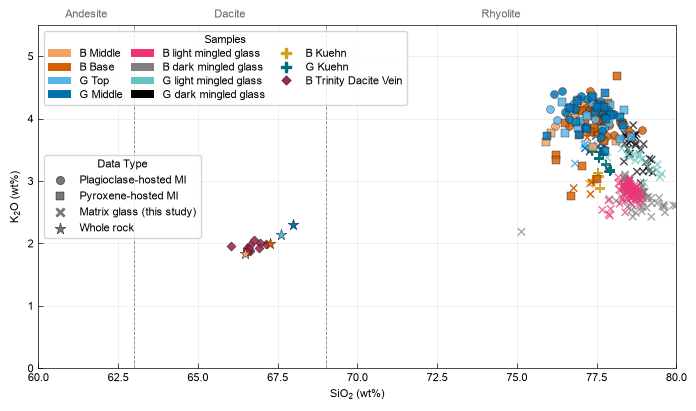

In [3]:
figure, axis = plt.subplots(figsize=(FIGURE_WIDTH_IN, FIGURE_HEIGHT_IN))
axis.grid(True, which='major', color='#D9D9D9', linewidth=0.4, alpha=0.75, zorder=0)
axis.set_axisbelow(True)
for silica_value in [63.0, 69.0]:
    axis.axvline(silica_value, color='#8C8C8C', linestyle='--', linewidth=0.65, zorder=1)
for silica_value, label in [(61.5, 'Andesite'), (66.0, 'Dacite'), (74.5, 'Rhyolite')]:
    axis.text(silica_value, 1.015, label, transform=axis.get_xaxis_transform(), ha='center', va='bottom', color='#666666', fontsize=ANNOTATION_SIZE_PT)

for plot_key in ['G dark', 'G light', 'B dark', 'B light']:
    subset = mingled_glass.loc[mingled_glass['plot_key'].eq(plot_key)]
    axis.scatter(subset[X_COLUMN], subset[Y_COLUMN], c=MINGLED_COLORS[plot_key], alpha=0.70, zorder=2, **SCATTER_STYLES['matrix_glass'])
for unit in ['B', 'G']:
    subset = kuehn_glass.loc[kuehn_glass['Unit'].eq(unit)]
    axis.scatter(subset[X_COLUMN], subset[Y_COLUMN], c=KUEHN_COLORS[unit], alpha=0.88, zorder=3, **SCATTER_STYLES['kuehn_glass'])
axis.scatter(dacite_vein_glass[X_COLUMN], dacite_vein_glass[Y_COLUMN], c=DACITE_VEIN_COLOR, alpha=0.90, zorder=4, **SCATTER_STYLES['dacite_vein'])
for sample_key in ['74D', '74A', '75', '76A']:
    subset = host_matrix_glass.loc[host_matrix_glass['sample_key'].eq(sample_key)]
    axis.scatter(subset[X_COLUMN], subset[Y_COLUMN], c=SAMPLE_COLORS[sample_key], alpha=0.96, zorder=5, **SCATTER_STYLES['matrix_glass'])
    for host_key in ['plag', 'pxy']:
        subset = melt_inclusions.loc[melt_inclusions['sample_key'].eq(sample_key) & melt_inclusions['host_key'].eq(host_key)]
        axis.scatter(subset[X_COLUMN], subset[Y_COLUMN], c=SAMPLE_COLORS[sample_key], alpha=0.82, zorder=6, **SCATTER_STYLES[host_key])
for sample_key in ['74D', '74A', '75', '76A']:
    subset = whole_rock.loc[whole_rock['sample_key'].eq(sample_key)]
    axis.scatter(subset[X_COLUMN], subset[Y_COLUMN], c=SAMPLE_COLORS[sample_key], zorder=7, **SCATTER_STYLES['whole_rock'])

axis.set(xlim=X_LIMITS, ylim=Y_LIMITS, xlabel='SiO$_2$ (wt%)', ylabel='K$_2$O (wt%)')
for spine in axis.spines.values():
    spine.set_visible(True)

sample_handles = [
    Patch(facecolor=SAMPLE_COLORS[key], edgecolor='none', label=SAMPLE_LABELS[key]) for key in ['74D', '74A', '75', '76A']
]
sample_handles += [
    Patch(facecolor=MINGLED_COLORS[key], edgecolor='none', label=MINGLED_LABELS[key]) for key in ['B light', 'B dark', 'G light', 'G dark']
]
sample_handles += [
    Line2D([], [], linestyle='none', marker=MARKER_PATHS['kuehn_glass'], color=KUEHN_COLORS['B'], markersize=MARKER_SPANS_PT['kuehn_glass'], label='B Kuehn'),
    Line2D([], [], linestyle='none', marker=MARKER_PATHS['kuehn_glass'], color=KUEHN_COLORS['G'], markersize=MARKER_SPANS_PT['kuehn_glass'], label='G Kuehn'),
    Line2D([], [], linestyle='none', marker=MARKER_PATHS['dacite_vein'], markerfacecolor=DACITE_VEIN_COLOR, markeredgecolor='black', markeredgewidth=MINIMUM_LINE_WIDTH_PT, markersize=MARKER_SPANS_PT['dacite_vein'], label='B Trinity Dacite Vein'),
]
samples_legend = axis.legend(handles=sample_handles, title='Samples', loc='upper left', ncol=3, columnspacing=0.8, labelspacing=0.3, frameon=True)
axis.add_artist(samples_legend)
data_type_handles = [
    Line2D([], [], linestyle='none', marker=MARKER_PATHS['plag'], markerfacecolor='#777777', markeredgecolor='black', markeredgewidth=MINIMUM_LINE_WIDTH_PT, markersize=MARKER_SPANS_PT['plag'], label='Plagioclase-hosted MI'),
    Line2D([], [], linestyle='none', marker=MARKER_PATHS['pxy'], markerfacecolor='#777777', markeredgecolor='black', markeredgewidth=MINIMUM_LINE_WIDTH_PT, markersize=MARKER_SPANS_PT['pxy'], label='Pyroxene-hosted MI'),
    Line2D([], [], linestyle='none', marker=MARKER_PATHS['matrix_glass'], color='#777777', markersize=MARKER_SPANS_PT['matrix_glass'], label='Matrix glass (this study)'),
    Line2D([], [], linestyle='none', marker=MARKER_PATHS['whole_rock'], markerfacecolor='#777777', markeredgecolor='black', markeredgewidth=MINIMUM_LINE_WIDTH_PT, markersize=MARKER_SPANS_PT['whole_rock'], label='Whole rock'),
]
axis.legend(handles=data_type_handles, title='Data Type', loc='center left', frameon=True)
figure.subplots_adjust(left=0.105, right=0.985, bottom=0.14, top=0.92)

pdf_path = OUTPUT_DIRECTORY / 'Figure_S08_SiO2_K2O.pdf'
png_path = OUTPUT_DIRECTORY / 'Figure_S08_SiO2_K2O.png'
svg_path = OUTPUT_DIRECTORY / 'Figure_S08_SiO2_K2O.svg'
figure.savefig(pdf_path, format='pdf', facecolor='white', transparent=False)
figure.savefig(png_path, format='png', dpi=EXPORT_DPI, facecolor='white', transparent=False)
figure.savefig(svg_path, format='svg', facecolor='white', transparent=False)
print('Saved:', pdf_path)
print('Saved:', png_path)
print('Saved:', svg_path)
plt.show()